# **Pemahaman Masalah dan Data**

Tujuan: Memprediksi listrik yang dihasilkan pembangkit per jam berdasarkan suhu, tekanan udara, tekanan vakum, dan kelembapan udara.

Pengguna: Operator dan Perencana Produksi di Pembangkit Listrik

Keputusan: Memperkirakan pasokan listrik per jam dan deteksi dini jika listrik yang dihasilkan lebih rendah dari seharusnya

Dataset Combined Cycle Power Plant, diakses pada Minggu, 10 November 2026 pada [link dataset](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) dengan lisensi CC BY 4.0

<table style="width:100%; border-collapse:collapse; font-size:18px;">
  <thead>
    <tr style="background-color:#e8e8e8;">
      <th style="padding:12px; border:1px solid #999; text-align:left;">Nama</th>
      <th style="padding:12px; border:1px solid #999; text-align:left;">Tipe</th>
      <th style="padding:12px; border:1px solid #999; text-align:left;">Arti</th>
      <th style="padding:12px; border:1px solid #999; text-align:left;">Satuan</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="padding:12px; border:1px solid #999;"><b>AT</b></td>
      <td style="padding:12px; border:1px solid #999;">float</td>
      <td style="padding:12px; border:1px solid #999;">Suhu lingkungan rata-rata per jam</td>
      <td style="padding:12px; border:1px solid #999;">°C</td>
    </tr>
    <tr>
      <td style="padding:12px; border:1px solid #999;"><b>V</b></td>
      <td style="padding:12px; border:1px solid #999;">float</td>
      <td style="padding:12px; border:1px solid #999;">Vakum buang rata-rata per jam</td>
      <td style="padding:12px; border:1px solid #999;">cmHg</td>
    </tr>
    <tr>
      <td style="padding:12px; border:1px solid #999;"><b>AP</b></td>
      <td style="padding:12px; border:1px solid #999;">float</td>
      <td style="padding:12px; border:1px solid #999;">Tekanan udara lingkungan rata-rata per jam</td>
      <td style="padding:12px; border:1px solid #999;">milibar</td>
    </tr>
    <tr>
      <td style="padding:12px; border:1px solid #999;"><b>RH</b></td>
      <td style="padding:12px; border:1px solid #999;">float</td>
      <td style="padding:12px; border:1px solid #999;">Kelembapan relatif rata-rata per jam</td>
      <td style="padding:12px; border:1px solid #999;">%</td>
    </tr>
    <tr>
      <td style="padding:12px; border:1px solid #999;"><b>PE</b></td>
      <td style="padding:12px; border:1px solid #999;">float</td>
      <td style="padding:12px; border:1px solid #999;">Keluaran energi listrik bersih per jam</td>
      <td style="padding:12px; border:1px solid #999;">MW</td>
    </tr>
  </tbody>
</table>

In [21]:
import pandas as pd
from google.colab import drive

SEED = 514

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/datasetpowerplant.xlsx'

df = pd.read_excel(file_path)

df = df.rename(columns={
    'AT': 'Suhu (°C)',
    'V': 'Tekanan_Vakum (cm Hg)',
    'AP': 'Tekanan_Udara (mbar)',
    'RH': 'Kelembapan_Udara (%)',
    'PE': 'Energi_Listrik (MW)'
})

df
df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Suhu (°C)              9568 non-null   float64
 1   Tekanan_Vakum (cm Hg)  9568 non-null   float64
 2   Tekanan_Udara (mbar)   9568 non-null   float64
 3   Kelembapan_Udara (%)   9568 non-null   float64
 4   Energi_Listrik (MW)    9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


# **Eksplorasi dan Visualisasi Data**

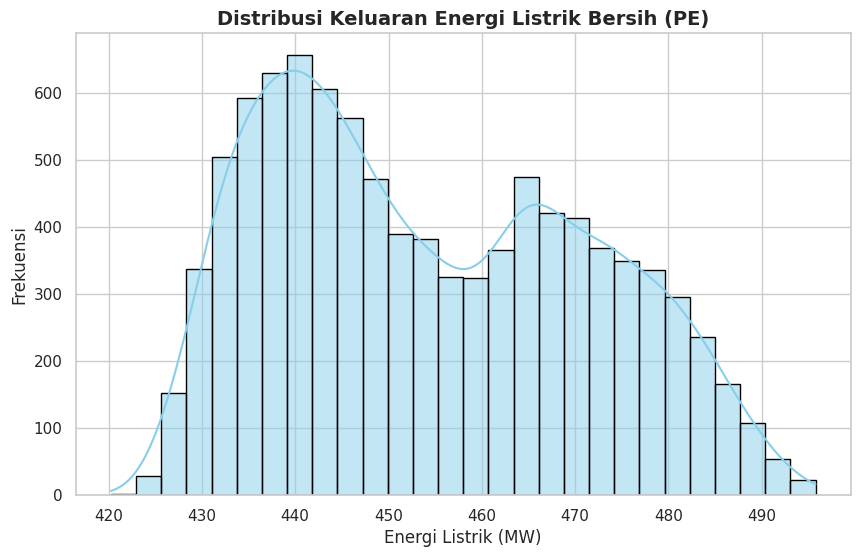

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.histplot(df['Energi_Listrik (MW)'], kde=True, color='skyblue', edgecolor='black')

plt.title('Distribusi Keluaran Energi Listrik Bersih (PE)', fontsize=14, fontweight='bold')
plt.xlabel('Energi Listrik (MW)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

plt.show()

Distribusi Keluaran Energi Listrik Bersih (PE) membentuk dua gunung, dengan puncak di sekitar 440 MW dan 465 MW, yang menunjukkan bahwa keluaran energi listrik paling sering berada pada kedua kisaran tersebut.

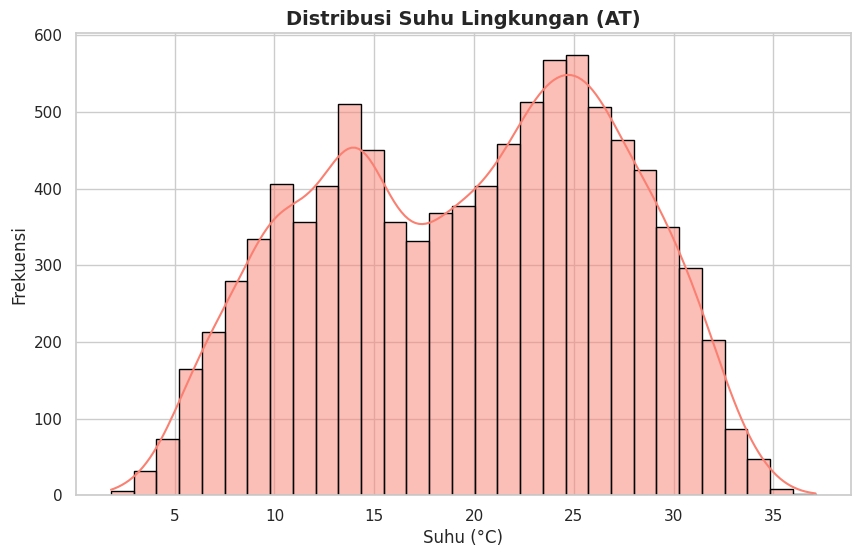

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Membuat plot
plt.figure(figsize=(10, 6))
sns.histplot(df['Suhu (°C)'], kde=True, color='salmon', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Suhu Lingkungan (AT)', fontsize=14, fontweight='bold')
plt.xlabel('Suhu (°C)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# Menampilkan plot
plt.show()

Distribusi Suhu Lingkungan (AT) membentuk dua gunung, dengan puncak di sekitar 14 °C dan 25 °C, yang menunjukkan bahwa suhu paling sering berada pada kedua kisaran tersebut.

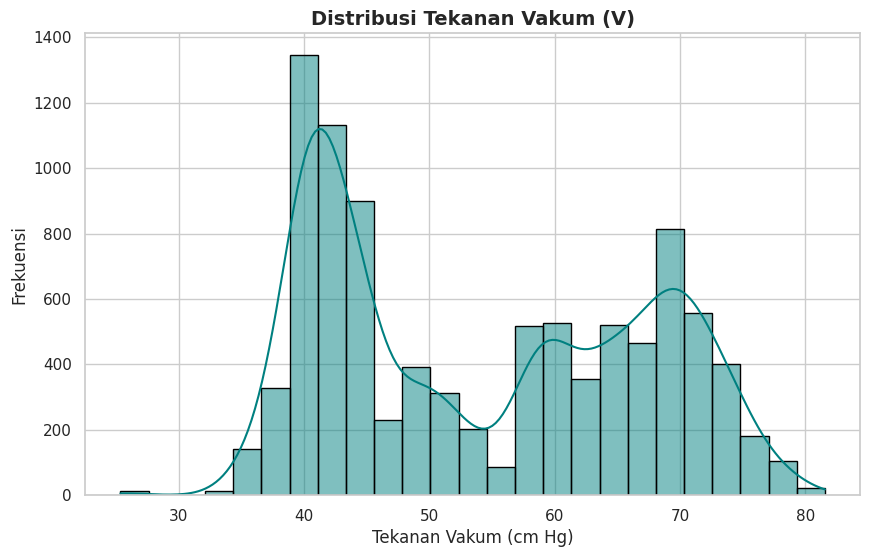

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Membuat plot
plt.figure(figsize=(10, 6))
sns.histplot(df['Tekanan_Vakum (cm Hg)'], kde=True, color='teal', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Tekanan Vakum (V)', fontsize=14, fontweight='bold')
plt.xlabel('Tekanan Vakum (cm Hg)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# Menampilkan plot
plt.show()

Distribusi Tekanan Vakum (V) membentuk dua gunung, dengan puncak di sekitar 41 cm Hg dan 69 cm Hg, yang menunjukkan bahwa tekanan vakum paling sering berada pada kedua kisaran tersebut.

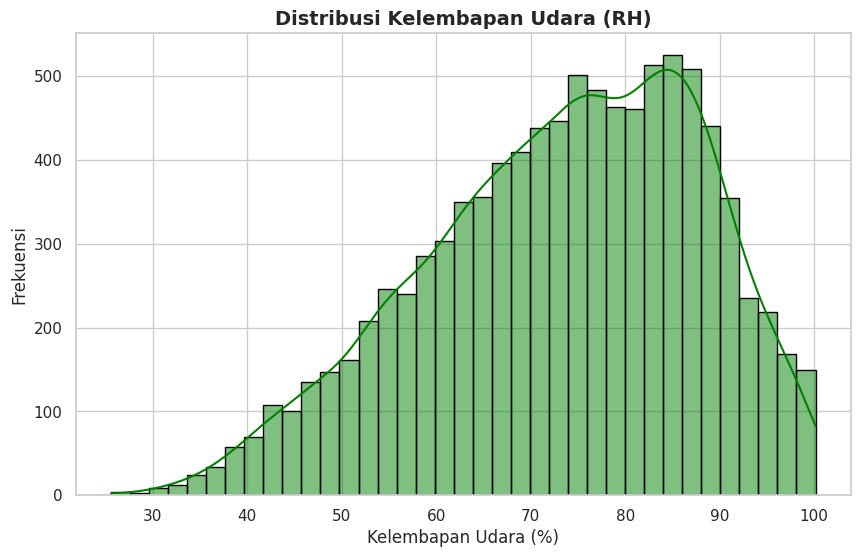

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Membuat plot
plt.figure(figsize=(10, 6))
sns.histplot(df['Kelembapan_Udara (%)'], kde=True, color='green', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Kelembapan Udara (RH)', fontsize=14, fontweight='bold')
plt.xlabel('Kelembapan Udara (%)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# Menampilkan plot
plt.show()

Distribusi Kelembapan Udara (RH) condong ke kanan dengan puncak di sekitar 75-85%, yang menunjukkan bahwa kelembapan paling sering berada pada kisaran tinggi tersebut.

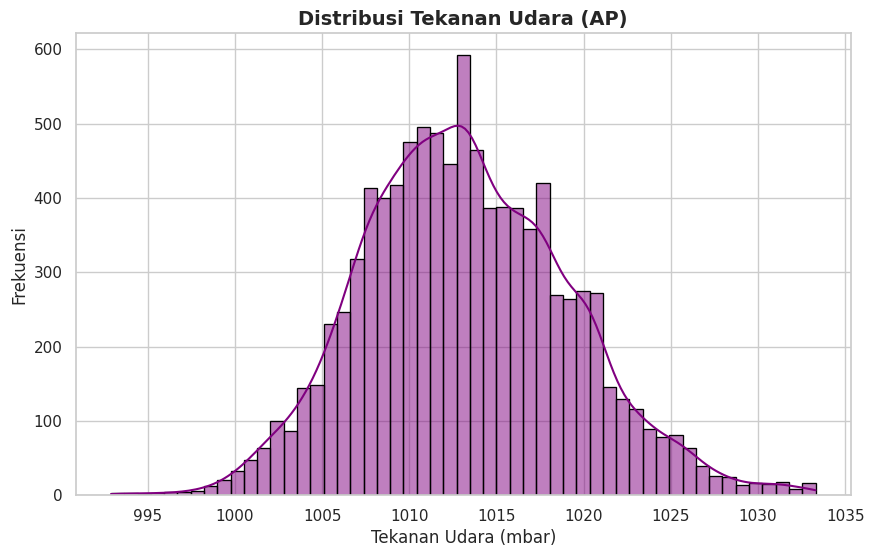

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Membuat plot
plt.figure(figsize=(10, 6))
sns.histplot(df['Tekanan_Udara (mbar)'], kde=True, color='purple', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Tekanan Udara (AP)', fontsize=14, fontweight='bold')
plt.xlabel('Tekanan Udara (mbar)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

# Menampilkan plot
plt.show()

Distribusi Tekanan Udara (AP) berbentuk lonceng dengan satu puncak di sekitar 1010-1015 mbar, yang menunjukkan bahwa tekanan udara paling sering berada pada kisaran tersebut.

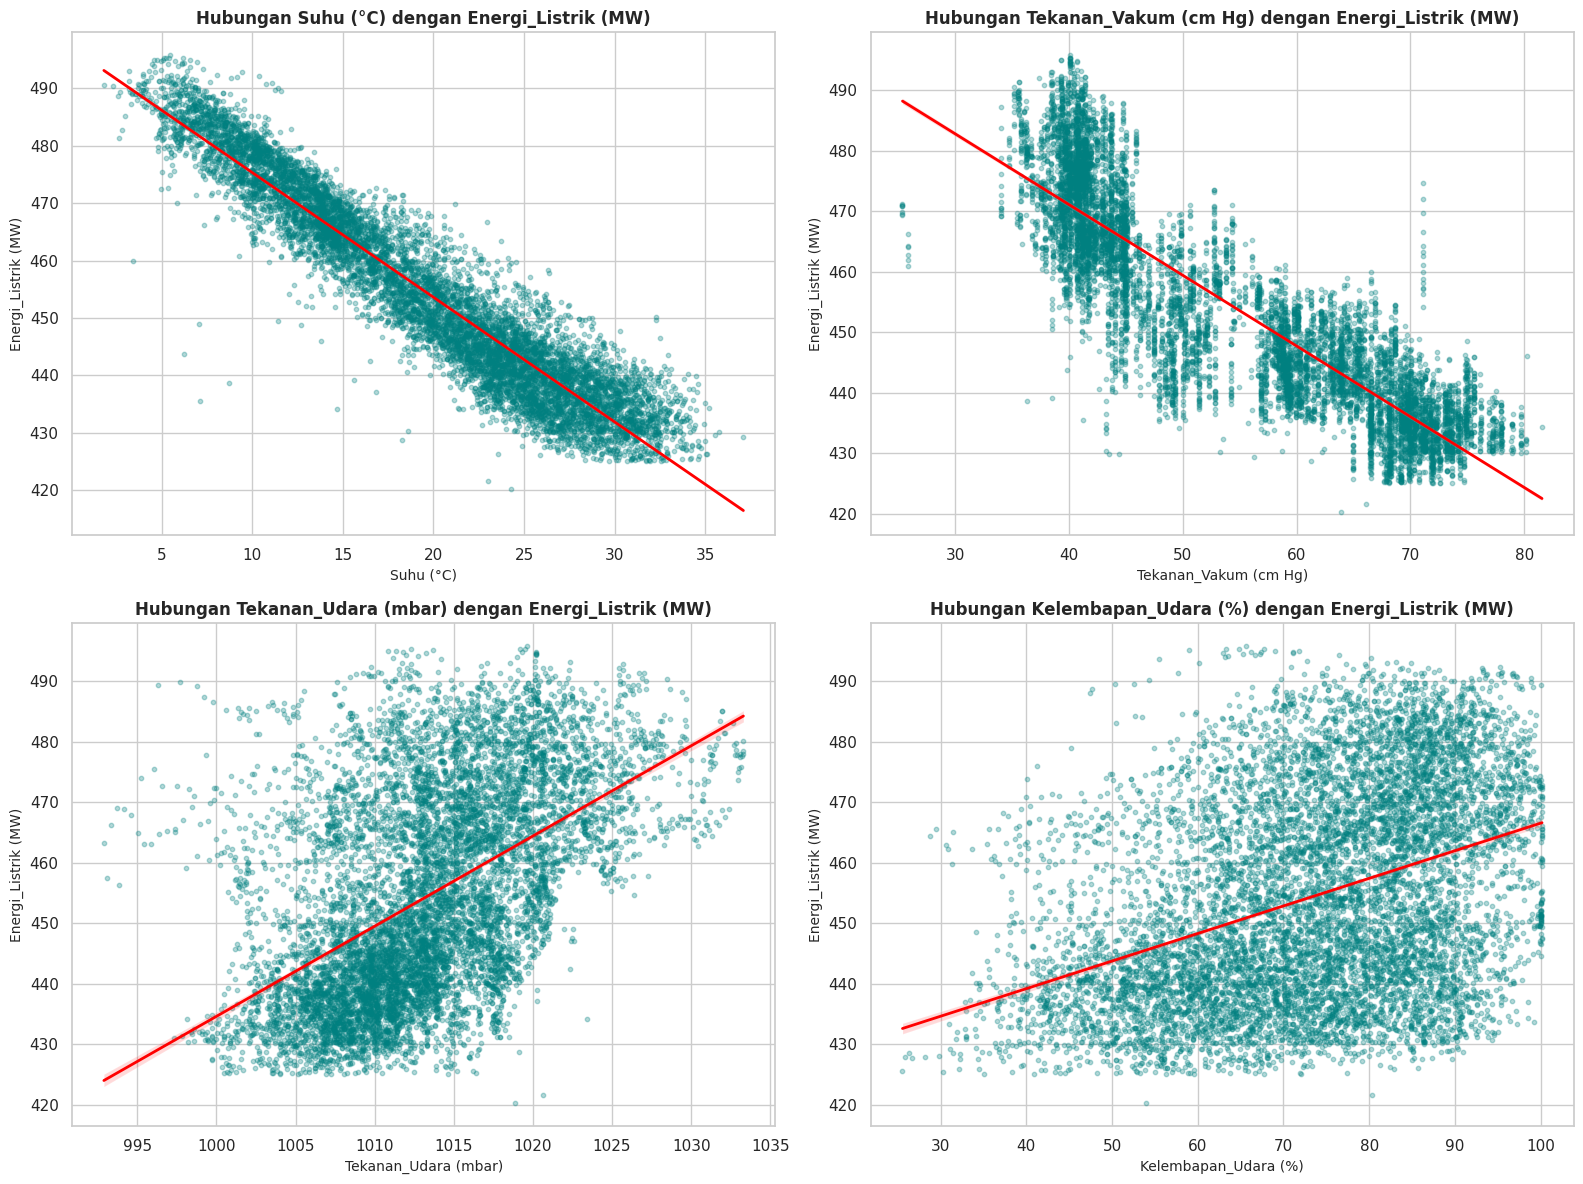

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menentukan fitur dan target
features = ['Suhu (°C)', 'Tekanan_Vakum (cm Hg)', 'Tekanan_Udara (mbar)', 'Kelembapan_Udara (%)']
target = 'Energi_Listrik (MW)'

# Membuat subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    # Menggunakan regplot untuk melihat tren linear hubungan
    sns.regplot(data=df, x=col, y=target, ax=axes[i],
                scatter_kws={'alpha':0.3, 'color': 'teal', 's': 10},
                line_kws={'color': 'red', 'linewidth': 2})
    axes[i].set_title(f'Hubungan {col} dengan {target}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel(target, fontsize=10)

plt.tight_layout()
plt.show()

Suhu (AT) dan tekanan vakum (V) memiliki hubungan negatif kuat dengan energi listrik, dengan suhu paling kuat karena titiknya rapat mengikuti garis. Tekanan udara (AP) dan kelembapan (RH) memiliki hubungan positif yang lebih lemah karena titiknya menyebar luas di sekitar garis.

**Keputusan Saya**

Grafik distribusi dan grafik hubungan fitur dengan target untuk memahami sebaran data dan pola hubungannya, sebagai dasar keputusan pra-pemrosesan dan pemodelan.

# **Pra-pemrosesan Data**

In [28]:
# 1. Missing value, kategori tidak konsisten, encoding
print(df.isna().sum())
print(df.dtypes)

Suhu (°C)                0
Tekanan_Vakum (cm Hg)    0
Tekanan_Udara (mbar)     0
Kelembapan_Udara (%)     0
Energi_Listrik (MW)      0
dtype: int64
Suhu (°C)                float64
Tekanan_Vakum (cm Hg)    float64
Tekanan_Udara (mbar)     float64
Kelembapan_Udara (%)     float64
Energi_Listrik (MW)      float64
dtype: object


In [29]:
# 2. Cek duplikat (sebelum dihapus)
print("Jumlah baris duplikat:", df.duplicated().sum())   # 41
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

Jumlah baris duplikat: 41


,Suhu (°C),Tekanan_Vakum (cm Hg),Tekanan_Udara (mbar),Kelembapan_Udara (%),Energi_Listrik (MW)
5045,6.03,41.17,1019.81,84.20,488.57
5320,6.03,41.17,1019.81,84.20,488.57
1186,6.06,41.17,1019.67,84.70,489.62
6008,6.06,41.17,1019.67,84.70,489.62
4261,6.40,41.17,1019.54,85.37,488.82
...,...,...,...,...,...
6227,29.23,75.60,1017.72,52.26,438.92
2649,29.45,75.60,1018.12,50.68,437.31
8882,29.45,75.60,1018.12,50.68,437.31
3814,29.51,75.60,1017.92,50.61,431.18


In [30]:
# 3. Tangani duplikat
n_awal = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print("Dibuang :", n_awal - len(df))
print("Sisa    :", len(df))
print("Duplikat:", df.duplicated().sum())

Dibuang : 41
Sisa    : 9527
Duplikat: 0


In [31]:
# 4. Bagi data latih-uji (sebelum fit apa pun)
X = df.drop(columns="Energi_Listrik (MW)")
y = df["Energi_Listrik (MW)"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(7621, 4) (1906, 4)


In [32]:
# 5. Outlier (IQR) dari data latih
Q1, Q3 = X_train.quantile(0.25), X_train.quantile(0.75)
IQR = Q3 - Q1
batas_bawah, batas_atas = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
is_outlier = (X_train < batas_bawah) | (X_train > batas_atas)
ringkasan = pd.DataFrame({
    "Batas bawah": batas_bawah.round(2), "Batas atas": batas_atas.round(2),
    "Outlier bawah": (X_train < batas_bawah).sum(),
    "Outlier atas": (X_train > batas_atas).sum(),
    "Total outlier": is_outlier.sum(),
    "Persen (%)": (is_outlier.mean() * 100).round(2)})
print(ringkasan)

                       Batas bawah  Batas atas  Outlier bawah  Outlier atas  \
Suhu (°C)                    -4.63       44.01              0             0   
Tekanan_Vakum (cm Hg)         4.64      103.68              0             0   
Tekanan_Udara (mbar)        996.94     1029.34             13            61   
Kelembapan_Udara (%)         30.92      117.04              9             0   

                       Total outlier  Persen (%)  
Suhu (°C)                          0        0.00  
Tekanan_Vakum (cm Hg)              0        0.00  
Tekanan_Udara (mbar)              74        0.97  
Kelembapan_Udara (%)               9        0.12  


In [34]:
# 6. Penanganan outlier (clip) + scaling, di dalam Pipeline/ColumnTransformer
class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X)
        q1, q3 = np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)
        iqr = q3 - q1
        self.low_, self.high_ = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        return self
    def transform(self, X):
        return np.clip(np.asarray(X), self.low_, self.high_)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("clip", IQRClipper()),
                      ("sc", StandardScaler())]), list(X_train.columns))])

**Keputusan Saya**

Tidak ada missing value dan semua kolom numerik, jadi tidak perlu encoding. Saya menghapus 41 baris duplikat sebelum membagi data agar tidak ada baris sama di data latih dan uji. Outlier pada fitur (Tekanan_Udara 74 baris, Kelembapan_Udara 9 baris) dideteksi dengan IQR dari data latih lalu di-clip, bukan dihapus, karena jumlahnya kecil dan nilainya masih wajar. Scaling memakai StandardScaler karena skala fitur berbeda jauh. Clip dan scaling ada di Pipeline dan hanya di-fit pada data latih agar tidak ada kebocoran data.

# **Pemodelan**

In [35]:
korelasi = X_train.corrwith(y_train).sort_values()
print(korelasi.round(3))
fitur_terbaik = korelasi.abs().idxmax()
print("Fitur terpilih:", fitur_terbaik)

Suhu (°C)               -0.948
Tekanan_Vakum (cm Hg)   -0.870
Kelembapan_Udara (%)     0.387
Tekanan_Udara (mbar)     0.513
dtype: float64
Fitur terpilih: Suhu (°C)


In [36]:
# 2. Siapkan 5-fold cross-validation (Jalur B: KFold, random_state = SEED)
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# 3. Fungsi Pipeline: clip outlier (IQR) + scaling + model
def buat(fitur, reg):
    pre = ColumnTransformer([("num", Pipeline([
        ("clip", IQRClipper()),
        ("sc", StandardScaler())]), fitur)])
    return Pipeline([("pre", pre), ("reg", reg)])

# 4. Tiga model yang diminta soal
semua = list(X_train.columns)
model = {
    "Dummy (mean)":     buat(semua, DummyRegressor(strategy="mean")),      # baseline
    "Linear sederhana": buat([fitur_terbaik], LinearRegression()),         # 1 fitur
    "Linear berganda":  buat(semua, LinearRegression()),                   # 4 fitur
}

In [40]:
# 5. Jalankan 5-fold CV pada DATA LATIH dan bandingkan ketiganya
hasil = {}
for nama, m in model.items():
    h = cross_validate(m, X_train, y_train, cv=cv, return_train_score=True,
                       scoring=["neg_mean_absolute_error",
                                "neg_root_mean_squared_error", "r2"])
    hasil[nama] = {
    "MAE CV":    -h["test_neg_mean_absolute_error"].mean(),
    "MAE latih": -h["train_neg_mean_absolute_error"].mean(),
    "RMSE CV":   -h["test_neg_root_mean_squared_error"].mean(),
    "RMSE latih":-h["train_neg_root_mean_squared_error"].mean(),
    "R2 CV":      h["test_r2"].mean(),
    "R2 latih":   h["train_r2"].mean(),
}

tabel_cv = pd.DataFrame(hasil).T.round(3)
print(tabel_cv)

                  MAE CV  MAE latih  RMSE CV  RMSE latih  R2 CV  R2 latih
Dummy (mean)      14.808     14.806   17.030      17.028 -0.001     0.000
Linear sederhana   4.283      4.281    5.418       5.417  0.898     0.899
Linear berganda    3.621      3.618    4.552       4.549  0.928     0.929


**Keputusan Saya**

Regresi linear sederhana (Suhu), regresi linear berganda (4 fitur), dan DummyRegressor dibandingkan dengan 5-fold cross-validation pada data latih untuk memilih model terbaik tanpa memakai data uji. Regresi berganda paling baik (MAE CV 3,621 MW dan R² CV 0,928, dibanding baseline 14,808 MW dan -0,001), dan tidak overfitting karena skor CV dan skor latih hampir sama.

# **Evaluasi dan Interpretasi**

In [41]:
# 1. Uji SETIAP model satu kali pada data uji, lalu hitung MAE, RMSE, R2
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred = {}
baris = {}
for nama, m in model.items():
    m.fit(X_train, y_train)            # latih pada seluruh data latih
    p = m.predict(X_test)              # uji satu kali pada data uji
    pred[nama] = p
    baris[nama] = {
        "MAE uji":   mean_absolute_error(y_test, p),
        "RMSE uji":  mean_squared_error(y_test, p) ** 0.5,
        "R2 uji":    r2_score(y_test, p),
        "R2 latih":  m.score(X_train, y_train),
    }

In [42]:
# 2. Tabel perbandingan model dengan baseline + skor latih vs uji (cek overfitting)
tabel_uji = pd.DataFrame(baris).T
tabel_uji["Selisih R2 (latih-uji)"] = tabel_uji["R2 latih"] - tabel_uji["R2 uji"]
print(tabel_uji.round(3))

                  MAE uji  RMSE uji  R2 uji  R2 latih  Selisih R2 (latih-uji)
Dummy (mean)       14.780    17.076  -0.000     0.000                   0.000
Linear sederhana    4.308     5.468   0.897     0.899                   0.001
Linear berganda     3.647     4.591   0.928     0.929                   0.001


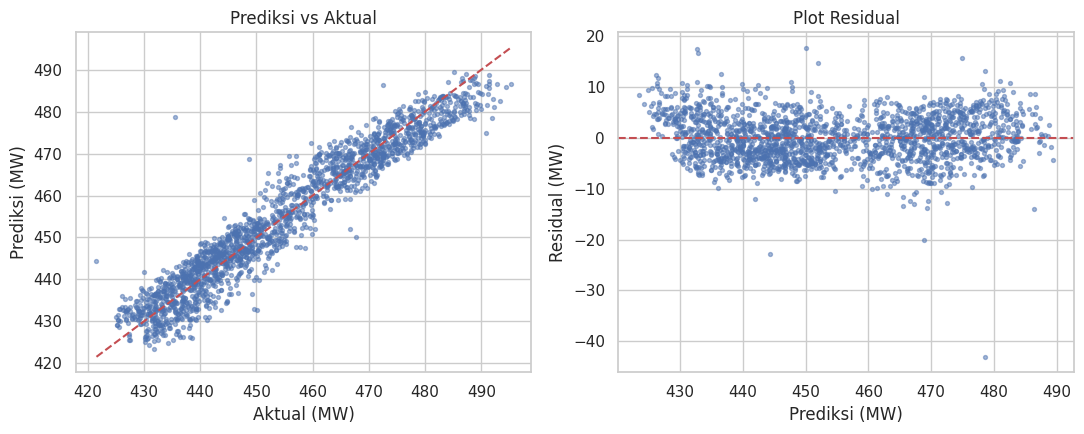

In [43]:
# 3. Plot prediksi vs aktual dan plot residual (model terbaik: linear berganda)
import matplotlib.pyplot as plt

p = pred["Linear berganda"]
residual = y_test - p

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(y_test, p, s=8, alpha=0.5)
lo, hi = y_test.min(), y_test.max()
axes[0].plot([lo, hi], [lo, hi], "r--")          # garis ideal: prediksi = aktual
axes[0].set_xlabel("Aktual (MW)")
axes[0].set_ylabel("Prediksi (MW)")
axes[0].set_title("Prediksi vs Aktual")

axes[1].scatter(p, residual, s=8, alpha=0.5)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Prediksi (MW)")
axes[1].set_ylabel("Residual (MW)")
axes[1].set_title("Plot Residual")

plt.tight_layout()
plt.show()

In [44]:
# 4. Koefisien regresi linear berganda (fitur sudah di-scale)
reg = model["Linear berganda"].named_steps["reg"]
koef = pd.Series(reg.coef_, index=semua)
print(koef.round(3))
print("Intercept:", round(reg.intercept_, 3))

Suhu (°C)               -14.645
Tekanan_Vakum (cm Hg)    -3.016
Tekanan_Udara (mbar)      0.357
Kelembapan_Udara (%)     -2.270
dtype: float64
Intercept: 454.274


**Keputusan Saya**

Ketiga model diuji satu kali pada data uji dan dibandingkan dengan skor latih untuk mengecek overfitting. Regresi linear berganda dipilih karena paling akurat (MAE uji 3,647 MW dan R² uji 0,928, dibanding baseline 14,780 MW dan 0,000), dan tidak overfitting karena selisih R² latih dan uji hanya 0,001. Koefisien menunjukkan Suhu paling berpengaruh (-14,645 MW per 1 simpangan baku).

# **Kesimpulan**

Model regresi linear berganda layak dipakai karena jauh lebih baik dari baseline, dan model inilah yang saya pilih. Pada data uji, MAE-nya 3,647 MW, sedangkan DummyRegressor 14,780 MW (error turun sekitar 75%). R² uji-nya 0,928, sedangkan baseline 0,000. Model ini juga lebih baik dari regresi linear sederhana (MAE 4,308 MW dan R² 0,897), jadi menambah fitur memang memberi perbaikan. Selisih R² latih dan uji hanya 0,001 dan MAE uji (3,647) hampir sama dengan MAE CV (3,621), sehingga model stabil dan tidak overfitting. Dari koefisien, Suhu paling berpengaruh (-14,645 MW per kenaikan 1 simpangan baku).

Bagi operator dan perencana produksi, model ini dapat dipakai untuk memperkirakan pasokan listrik per jam dari kondisi lingkungan, dengan toleransi rata-rata sekitar 3,6 MW (sekitar 0,8% dari rata-rata 454 MW). Jika listrik aktual berada jauh di bawah prediksi, melebihi kisaran galat normal model, hal itu dapat menjadi tanda awal untuk memeriksa kondisi pembangkit.

Keterbatasannya, model hanya linear sehingga belum tentu menangkap hubungan non-linear (misalnya pola Tekanan_Vakum yang mengelompok), hanya memakai 4 fitur lingkungan, dan datanya berasal dari satu pembangkit tanpa informasi waktu, sehingga belum tentu berlaku untuk pembangkit lain atau pola musiman. Sebagai saran perbaikan, dapat dicoba model non-linear (misalnya regresi polinomial atau model berbasis pohon) yang dibandingkan lewat cross-validation, menambah fitur seperti waktu atau beban operasi, dan menguji model pada data pembangkit lain.